# Notebook Prediksi PM2.5 Jakarta
Tujuan: memahami data, membersihkan, dan menemukan pola untuk feature selection

## Setup

In [2]:
%pip install ipywidgets

  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
Using cached ipywidgets-8.1.9-py3-none-any.whl (140 kB)
Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl (217 kB)
Using cached widgetsnbextension-4.0.16-py3-none-any.whl (2.2 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Import Library
import os
import warnings

# Data Related
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from darts.dataprocessing.transformers import Scaler
from scipy.stats import ks_2samp
from sklearn.model_selection import TimeSeriesSplit

# Model Builders
import joblib
import lightgbm as lgb
import optuna
import torch
from darts import TimeSeries
from darts.models import BlockRNNModel, TFTModel

# Evaluation
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Versioning
import mlflow
import wandb

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [ ]:
DATA_PATH = "../data/dataset/air_quality_historical.csv"
CLEAN_PATH = "../data/dataset/air_quality_clean.csv"
MODEL_PATH = "../models/model.joblib"

df = pd.read_csv(DATA_PATH)
POLUTAN = df.drop(columns=["us_aqi", "european_aqi"]).columns

AQI = ["us_aqi", "european_aqi"]

BAD_DATES = ["2022-12-24", "2022-12-15"]
EXOG = ["pm10", "carbon_monoxide", "nitrogen_dioxide", "ozone", "aerosol_optical_depth"]
LAGS = [1, 2, 3, 7, 14]

TEST_DAYS, SEED, N_TRIALS, N_EPOCHS = 180, 42, 30, 30
MIN_IMPROVEMENT = 0.05
os.makedirs("models", exist_ok=True)

In [ ]:
mlflow.set_experiment("pm25-jakarta")

def log_run(name: str, params: dict, metrics: dict) -> None:
    with mlflow.start_run(run_name=name):
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)
    with wandb.init(project="pm25-jakarta", name=name, config=params, reinit=True) as run:
        run.log(metrics)

## Load Data & EDA

In [9]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   1298 non-null   datetime64[us]
 1   pm10                   1295 non-null   float64       
 2   pm2_5                  1295 non-null   float64       
 3   carbon_monoxide        1295 non-null   float64       
 4   nitrogen_dioxide       1295 non-null   float64       
 5   sulphur_dioxide        1295 non-null   float64       
 6   ozone                  1295 non-null   float64       
 7   aerosol_optical_depth  1295 non-null   float64       
 8   dust                   1295 non-null   float64       
 9   uv_index               1295 non-null   float64       
 10  us_aqi                 1294 non-null   float64       
 11  european_aqi           1294 non-null   float64       
dtypes: datetime64[us](1), float64(11)
memory usage: 121.8 KB


In [10]:
raw[raw.drop(columns="date").isna().any(axis=1)]

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,120.764706,83.923529,2635.176471,82.235294,23.894118,186.235294,1.228824,0.0,1.473529,NaN,NaN


In [11]:
raw.nsmallest(10, "pm2_5")[["date", "pm2_5", "pm10", "carbon_monoxide", "us_aqi"]]

,date,pm2_5,pm10,carbon_monoxide,us_aqi
136,2022-12-15,0.641667,0.920833,60.708333,13.750000
135,2022-12-14,0.712500,1.033333,59.333333,32.041667
150,2022-12-29,11.512500,16.795833,891.208333,45.375000
592,2024-03-15,12.408333,17.929167,596.750000,58.625000
155,2023-01-03,12.591667,18.195833,1008.458333,51.458333
177,2023-01-25,12.887500,18.654167,998.250000,47.583333
154,2023-01-02,13.175000,19.162500,1019.125000,56.416667
152,2022-12-31,13.375000,19.450000,789.708333,57.875000
153,2023-01-01,13.666667,19.933333,1071.916667,46.083333
593,2024-03-16,13.770833,19.862500,698.208333,53.458333


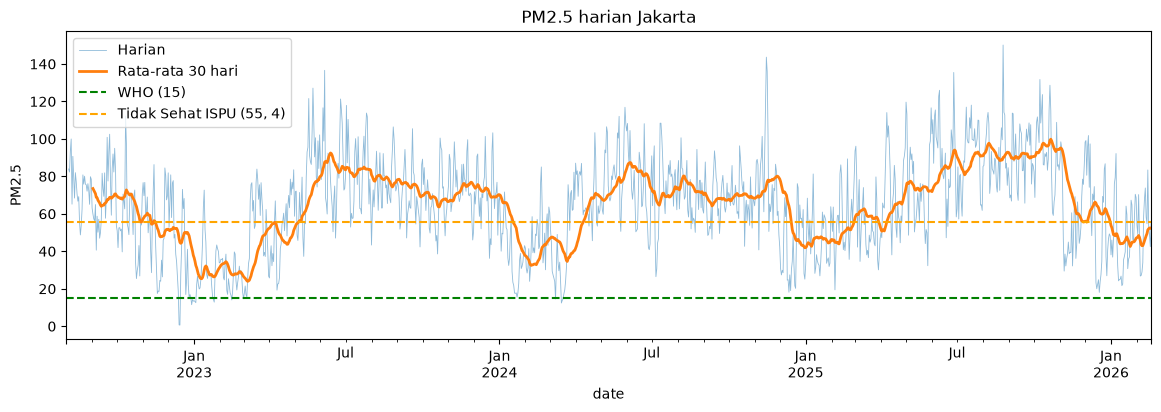

Hari di atas batas Tidak Sehat: 65.87%


In [14]:
s = raw.set_index("date")["pm2_5"]
ax = s.plot(figsize=(14,4), lw=0.6, alpha=0.5, label="Harian")
s.rolling(30).mean().plot(ax=ax, lw=2, label="Rata-rata 30 hari")
ax.axhline(15, color="green", ls="--", label="WHO (15)")
ax.axhline(55.4, color="orange", ls="--", label="Tidak Sehat ISPU (55, 4)")
ax.set(title="PM2.5 harian Jakarta", ylabel="PM2.5")
ax.legend()
plt.show()
print(f"Hari di atas batas Tidak Sehat: {(s > 55.4).mean():.2%}")

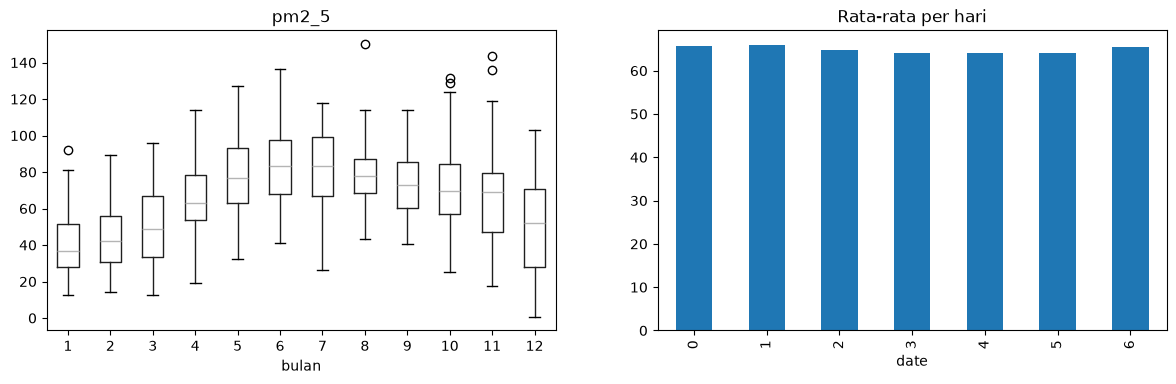

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw.assign(bulan=raw["date"].dt.month).boxplot(column="pm2_5", by="bulan", ax=axes[0], grid=False)
raw.groupby(raw["date"].dt.dayofweek)["pm2_5"].mean().plot.bar(ax=axes[1], title="Rata-rata per hari")
fig.suptitle("")
plt.show()

### **Temuan:** 
Musim tertinggi/terendah **Juni / Januari**, pola mingguan **65.87%** hari Tidak Sehat.
14-15 Des 2022 semua polutan dan AQI anjlok ~10x bersamaan berasal dari error sumber data.
Diganti NaN lalu diinterpolasi, tidak di-drop karena posisinya di tengah urutan waktu.